# Logistic-regression classification

OARL organelle predictions provide 30 morphometric and inter-organelle descriptors
per crop. A logistic classifier uses these descriptors to predict mitochondrial
perturbation.

The examples use the first control and the first ETC-treated tomogram in the
classification test manifest. These two samples illustrate inference; they do
not estimate performance on the full test set. Labels are **0 = control** and
**1 = ETC-perturbed**.

Install `requirements-notebooks.txt`, extract the classification dataset next to
`OARL/`, and place the downloaded weights in `checkpoints/` as described in the
[README](../README.md#data-and-model-weights). Set `DATA_DIR` below if needed.
The notebook runs on CPU or CUDA and reads ODT only.

In [1]:
from pathlib import Path
import csv
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch
from torch.utils.data import DataLoader

ROOT = Path(".") if Path("oarl_net").is_dir() else Path("..")
sys.path.insert(0, str(ROOT))
from oarl_net import Config, ODTDataset, create_model, load_tomograms
from oarl_net.checkpoint import load_weights

torch.set_num_threads(4)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = ROOT / ".." / "classification_dataset"
BATCH_SIZE = 3
print(f"Device: {DEVICE}")

Device: cpu


## Load two tomograms

In [2]:
cfg = Config()
test_tomograms = load_tomograms(
    ROOT / "metadata/tomograms.csv", DATA_DIR, task="classification", split="test")
# The first test tomogram of each class in manifest order.
selected = [next(t for t in test_tomograms if t.label == label) for label in (0, 1)]
dataset = ODTDataset(selected, cfg.data, augment=False, use_subimages=True,
                     classification_only=True, in_memory=True)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
class_names = {0: "Control", 1: "ETC-perturbed"}
for t in selected:
    print(f"{t.id}: {t.chemical}; reference = {class_names[t.label]}")

Loading tomograms:   0%|          | 0/2 [00:00<?, ?it/s]

Loading tomograms:  50%|█████     | 1/2 [00:00<00:00,  4.92it/s]

Loading tomograms: 100%|██████████| 2/2 [00:00<00:00,  5.08it/s]

Loading tomograms: 100%|██████████| 2/2 [00:00<00:00,  5.05it/s]

odt_0610: Ctrl; reference = Control
odt_0656: Antimycin; reference = ETC-perturbed


## Predict organelle masks and extract features

For each crop, segmentation probabilities are thresholded at 0.5. The feature
vector contains eight descriptors per organelle and six pairwise descriptors.
RI intensity statistics use the **mean projection of the seven normalized slices**.
See [feature definitions](../docs/classification.md#the-30-descriptors) for units,
component aggregation and empty-mask handling.

In [3]:
from oarl_net.morphometrics import FEATURE_NAMES, MorphometricClassifier
from predict_logistic_regression import predict_features

model = create_model(cfg.model)
load_weights(model, ROOT / "checkpoints/segmentation.pth")
model = model.to(DEVICE).eval()
features = predict_features(model, loader, DEVICE)
for key in features:
    features[key] = np.asarray(features[key])
    print(f"{key}: {features[key].shape[0]} crops × {features[key].shape[1]} features")
del model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

loaded 417 tensors from ../checkpoints/segmentation.pth (epoch 244)


odt_0610: 9 crops × 30 features
odt_0656: 9 crops × 30 features


## Apply the saved logistic classifier

The JSON file contains the training-set mean and scale, 30 coefficients and an
intercept. The model was fitted with `StandardScaler` and L2-regularized
`LogisticRegression(C=1, solver="liblinear", class_weight="balanced")`.
No fitting is performed on these example inputs.

For standardized features $z$, the crop score is $p = \mathrm{sigmoid}(w^Tz+b)$.
The mean of the nine crop probabilities is the tomogram score; a score above
0.5 gives class 1.

In [4]:
classifier = MorphometricClassifier(ROOT / "checkpoints/logistic_regression.json")
probabilities = {key: classifier.predict_probability(values)
                 for key, values in features.items()}
predictions = {key: int(p.mean() > 0.5) for key, p in probabilities.items()}

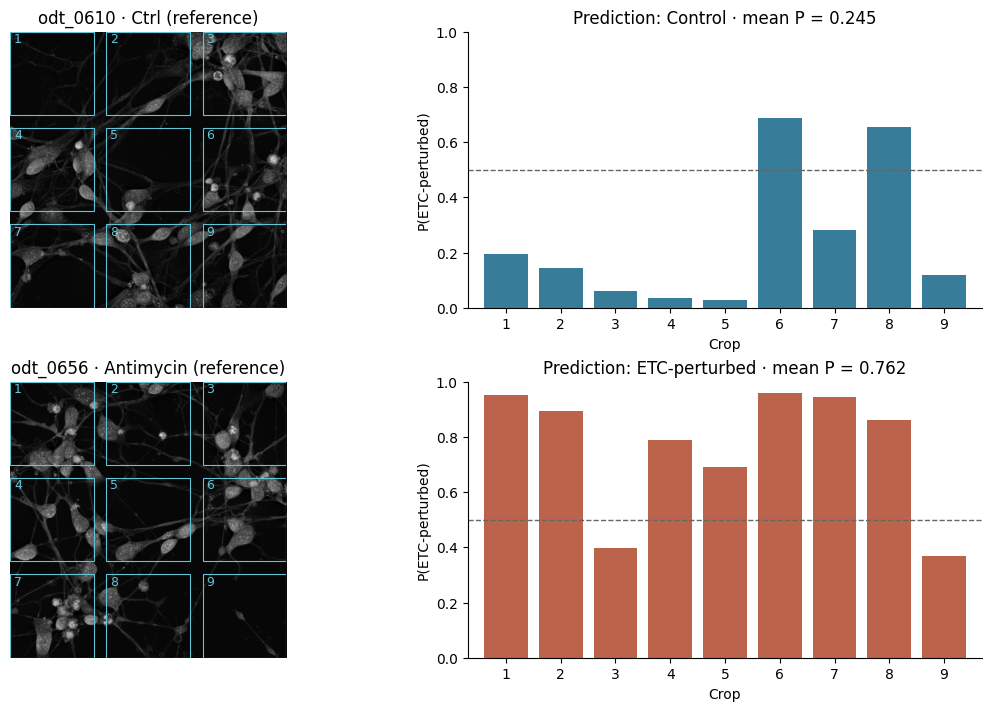

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for row, tomogram in enumerate(selected):
    ax = axes[row, 0]
    ax.imshow(dataset.images[row].max(axis=2), cmap="gray", vmin=0, vmax=1)
    for crop, (y, x) in enumerate(dataset.subimage_positions):
        ax.add_patch(Rectangle((x, y), cfg.data.crop_size, cfg.data.crop_size,
                               fill=False, edgecolor="#62c4d4", linewidth=0.8))
        ax.text(x + 10, y + 28, str(crop + 1), color="#62c4d4", fontsize=9)
    ax.set_title(f"{tomogram.id} · {tomogram.chemical} (reference)")
    ax.axis("off")
    p = np.asarray(probabilities[tomogram.id])
    prediction = predictions[tomogram.id]
    ax = axes[row, 1]
    ax.bar(np.arange(1, 10), p, color="#bc634b" if prediction else "#377d99")
    ax.axhline(0.5, color="0.4", linestyle="--", linewidth=1)
    ax.set(xlim=(0.3, 9.7), ylim=(0, 1), xticks=range(1, 10),
           xlabel="Crop", ylabel="P(ETC-perturbed)",
           title=f"Prediction: {class_names[prediction]} · mean P = {p.mean():.3f}")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Inspect the fitted coefficients

Coefficients refer to standardized features. Positive values increase the crop
log-odds of ETC perturbation, holding the other features fixed. The plot shows
the ten coefficients with the largest absolute values; it does not establish
causal effects.

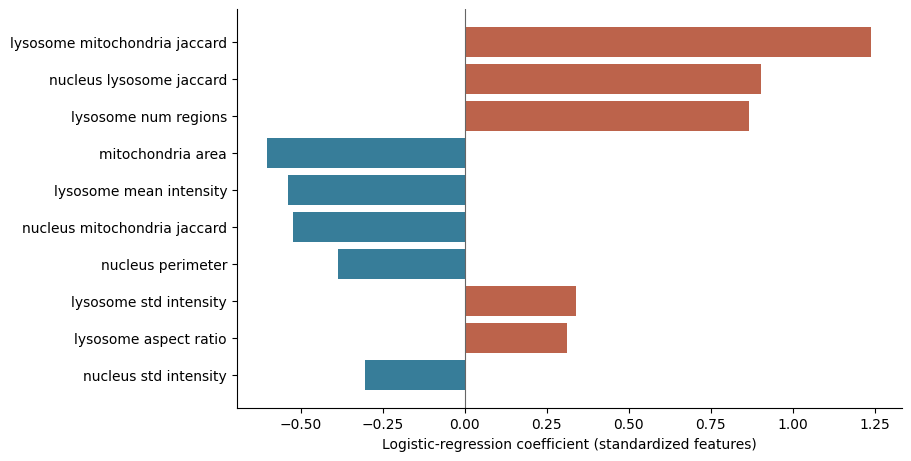

In [6]:
order = np.argsort(np.abs(classifier.coef))[-10:]
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
coef = classifier.coef[order]
ax.barh([FEATURE_NAMES[i].replace("_", " ") for i in order], coef,
        color=["#bc634b" if value > 0 else "#377d99" for value in coef])
ax.axvline(0, color="0.4", linewidth=0.8)
ax.set_xlabel("Logistic-regression coefficient (standardized features)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Save predictions and feature vectors

In [7]:
output = ROOT / "predictions" / "logistic_regression"
output.mkdir(parents=True, exist_ok=True)
with (output / "predictions.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["tomogram", "chemical", "label", "prediction", "mean_probability",
                     "crop_probabilities"])
    for t in selected:
        p = np.asarray(probabilities[t.id])
        writer.writerow([t.id, t.chemical, t.label, predictions[t.id], float(p.mean()),
                         ";".join(f"{x:.8f}" for x in p)])
print(f"Saved {len(selected)} predictions to predictions/logistic_regression/predictions.csv")
with (output / "features.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["tomogram", "crop", *FEATURE_NAMES])
    for t in selected:
        for crop, values in enumerate(features[t.id], start=1):
            writer.writerow([t.id, crop, *values])
print("Saved crop features to predictions/logistic_regression/features.csv")

Saved 2 predictions to predictions/logistic_regression/predictions.csv
Saved crop features to predictions/logistic_regression/features.csv


For a larger batch, use `predict_logistic_regression.py`. The [neural-network
example](classification_neural_network.ipynb) predicts from learned encoder features.